# **Option Pricing: Black–Scholes vs Monte Carlo**

> ### **European Option Contracts (Calls & Puts)**

A **European option** is a derivative contract that can be exercised only at maturity $T$.
1. **Call**: gives the holder the right (not the obligation) to buy the underlying at maturity $T$ for a pre-agreed strike $K$.
2. **Put**: gives the holder the right to sell the underlying at maturity $T$ for strike $K$.

**Payoff at maturity**
Let $S_T$ be the underlying price at maturity.

$$C_T = (S_T - K)^+ = \max(S_T - K, 0)$$
$$P_T = (K - S_T)^+ = \max(K - S_T, 0)$$

#### **Basic intuition**
- The call is valuable when $S_T > K$ (in-the-money, ITM), otherwise it expires worthless.
- The put is valuable when $S_T < K$ (ITM), otherwise it expires worthless.

**Note that $\rightarrow$** The option price at time $t=0$, denoted $C_0$ or $P_0$, is the value today of that uncertain payoff at time $T$.

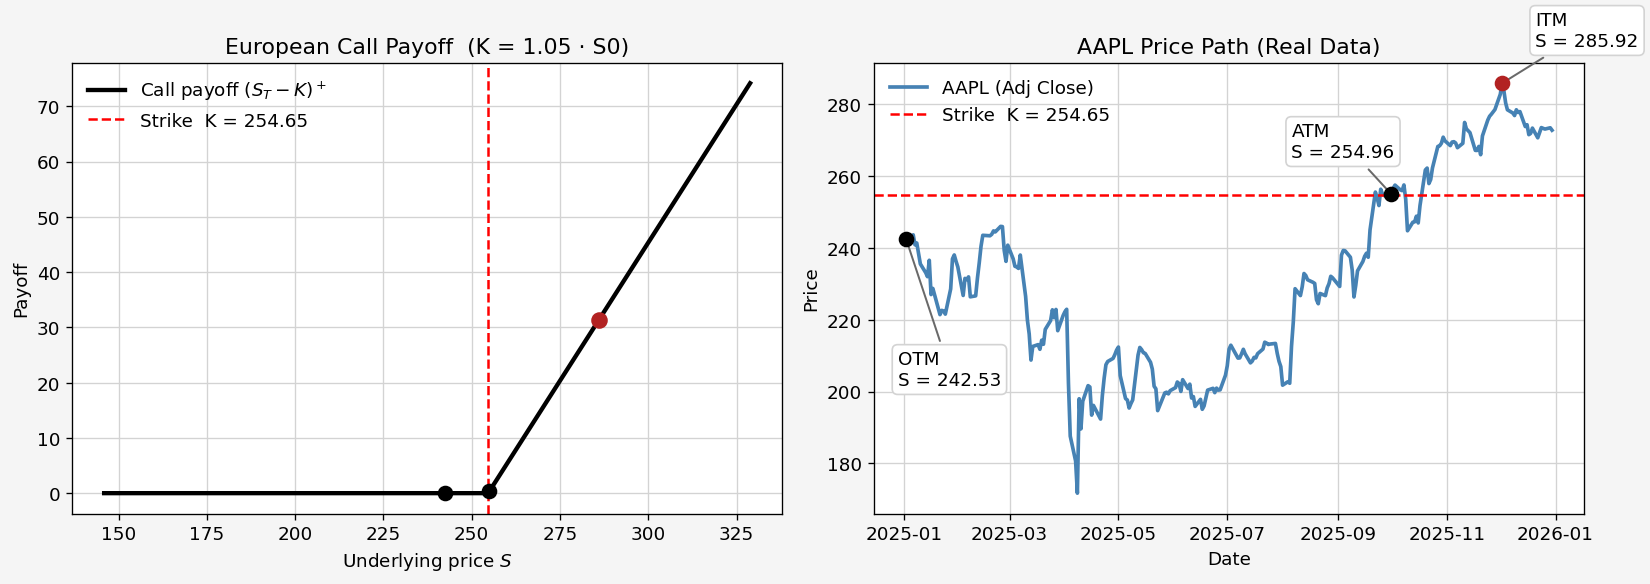

In [ ]:
# Libraries
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from math import erf, sqrt, log, exp

# -----------------------
# 1) Download data
# -----------------------
TICKER = "AAPL"
START  = "2025-01-01"
END    = "2025-12-31"

df = yf.download(TICKER, start=START, end=END, progress=False, auto_adjust=True)
px = df["Close"].dropna()

dates = px.index
path = px.to_numpy().ravel().astype(float)

S0 = float(path[0])
K = 1.05 * S0  # 5% OTM at inception

# -----------------------
# 2) Helpers
# -----------------------
def call_payoff(S, K):
    # Works for scalars or arrays; returns same "shape"
    return np.maximum(S - K, 0.0)

# Payoff curve (left)
S_grid = np.linspace(0.85 * path.min(), 1.15 * path.max(), 400)
payoff_grid = call_payoff(S_grid, K)

# -----------------------
# 3) Pick 3 anchor points (OTM / ATM / ITM)
# -----------------------
i_otm = 0
i_atm = int(np.argmin(np.abs(path - K)))   # closest-to-strike point
i_itm = int(np.argmax(path))              # max price point (best chance to be ITM)

p_otm = float(path[i_otm])
p_atm = float(path[i_atm])
p_itm = float(path[i_itm])

# If even the max never crosses K, label as "OTM (never ITM)"
itm_text = "ITM" if p_itm > K else "OTM (never ITM)"

# -----------------------
# 4) Styling (light)
# -----------------------
plt.rcParams.update({
    "figure.facecolor": "whitesmoke",
    "axes.facecolor": "white",
    "grid.color": "lightgray",
    "axes.edgecolor": "black",
    "axes.labelcolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "font.size": 11,
})

# Label/point colors (as requested)
otm_atm_point_color = "black"
itm_point_color     = "darkorange"  # same as payoff curve

arrow_color = "dimgray"

# -----------------------
# 5) Plot
# -----------------------
fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# ---- LEFT: Payoff diagram ----
axL.plot(S_grid, payoff_grid, lw=2.6, color="black",
         label=r"Call payoff $(S_T-K)^+$")

axL.axvline(K, ls="--", lw=1.5, color="red",
            label=f"Strike  K = {K:.2f}")

# Points on payoff curve
payoff_otm = call_payoff(p_otm, K)
payoff_atm = call_payoff(p_atm, K)
payoff_itm = call_payoff(p_itm, K)

# OTM & ATM steelblue
axL.scatter(p_otm, payoff_otm, s=70, color="black", zorder=5)
axL.scatter(p_atm, payoff_atm, s=70, color="black", zorder=5)

# ITM firebrick
axL.scatter(p_itm, payoff_itm, s=80, color="firebrick", zorder=6)

axL.set_title("European Call Payoff  (K = 1.05 · S0)")
axL.set_xlabel("Underlying price $S$")
axL.set_ylabel("Payoff")
axL.grid(True)
axL.legend(frameon=False)


# ---- RIGHT: Price Path ----
axR.plot(dates, path, lw=2.2, color="steelblue",
         label=f"{TICKER} (Adj Close)")

axR.axhline(K, ls="--", lw=1.5, color="red",
            label=f"Strike  K = {K:.2f}")

axR.set_title(f"{TICKER} Price Path (Real Data)")
axR.set_xlabel("Date")
axR.set_ylabel("Price")
axR.grid(True)
axR.legend(frameon=False)

axR.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axR.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))


# -----------------------
# Labels + points (RIGHT)
# -----------------------

def add_label(ax, label, idx, price, xytext, color):
    d = dates[idx]

    ax.scatter(d, price, s=70, color=color, zorder=6)

    ax.annotate(
        f"{label}\nS = {price:.2f}",
        xy=(d, price),
        xytext=xytext,
        textcoords="offset points",
        ha="left",
        va="bottom",
        bbox=dict(boxstyle="round,pad=0.30",
                  fc="white", ec="lightgray"),
        arrowprops=dict(arrowstyle="-", lw=1.2, color="dimgray"),
    )

# OTM
add_label(axR, "OTM", i_otm, p_otm, xytext=(-5, -90), color="black")

# ATM
add_label(axR, "ATM", i_atm, p_atm, xytext=(-60, 20), color="black")

# ITM
add_label(axR, "ITM", i_itm, p_itm, xytext=(20, 20), color="firebrick")

plt.tight_layout()
plt.show()

**Note that $\rightarrow$** The right panel is a realized historical path, not a simulated terminal distribution. In the model, $S_T$ is a random variable; here we use historical prices only for visualization of moneyness.

#### **What exactly is $S_T$?**
In a European option, the payoff is determined only at maturity $T$.
That is why the random variable that matters is the terminal price:

$$S_T := \text{the underlying price at time } T.$$

For a European call,

$$\text{Payoff at }T = (S_T - K)^+ = \max(S_T - K,0).$$

So the option is essentially a claim on the distribution of $S_T$.

> ### **Modeling the Underlying with GBM**

A common baseline model for equity prices is **Geometric Brownian Motion (GBM)**:

$$dS_t = \mu S_t\,dt + \sigma S_t\,dW_t,$$

where:
- $S_t$ is the asset price,
- $\mu$ is the (real-world) drift,
- $\sigma > 0$ is the volatility,
- $W_t$ is a standard Brownian motion.


It is often easier to work with log-prices. By Itô's Lemma, GBM implies:

$$
d(\ln S_t) = \left(\mu - \tfrac{1}{2}\sigma^2\right)\!dt + \sigma\,dW_t.
$$

Integrating from $0$ to $T$ gives the closed-form solution:

$$
\ln S_T = \ln S_0 + \left(\mu - \tfrac{1}{2}\sigma^2\right)T + \sigma W_T.
$$

Since $W_T \sim \mathcal{N}(0,T)$, it follows that

$$
\ln S_T \sim \mathcal{N}\!\left(\ln S_0 + \left(\mu - \tfrac{1}{2}\sigma^2\right)T,\; \sigma^2 T\right).
$$

Therefore, **$S_T$ is lognormally distributed**:

$$
S_T \sim \text{LogNormal}\!\left(\ln S_0 + \left(\mu - \tfrac{1}{2}\sigma^2\right)T,\; \sigma^2 T\right).
$$

#### **Two Key Implications**

**1. Why the option payoff is asymmetric**

The payoff $(S_T-K)^+$ is zero whenever $S_T \le K$, but grows linearly when $S_T > K$.
So the option value depends heavily on the **right tail** of the $S_T$ distribution.

**2. What we can estimate from historical data**

Under GBM, the distribution of log-returns over $\Delta t$ is normal:

$$
\ln\left(\frac{S_{t+\Delta t}}{S_t}\right)
\sim \mathcal{N}\!\left(\left(\mu - \tfrac{1}{2}\sigma^2\right)\Delta t,\; \sigma^2 \Delta t\right).
$$

This motivates estimating $\mu$ and $\sigma$ from historical log-returns.

But here is the crucial point for pricing:

**Note that $\rightarrow$** Even if we estimate $\mu$ under the real-world measure $\mathbb{P}$, option pricing will later replace $\mu$ with $r$ under the risk-neutral measure $\mathbb{Q}$.

That is the bridge to the next section: **risk-neutral pricing**.


> ### **From the Real-World Measure $(\mathbb{P})$ to the Pricing Measure $(\mathbb{Q})$**

So far, we modeled the underlying under the real-world probability measure $(\mathbb{P})$:

$$
dS_t = \mu S_t\,dt + \sigma S_t\,dW_t^{\mathbb{P}}.
$$

This is useful to describe how prices might evolve historically, but it does not directly tell us how to price.

The question is: *Why shouldn't the option price depend on the historical drift $\mu$?*


> ### **No-Arbitrage Intuition**

An option price is not a “forecast” of its payoff.  
It is the **no-arbitrage price**: the price that prevents free profits (arbitrage) when the option can be traded and hedged.

If a claim can be replicated (or hedged) using:
- the underlying stock $S_t$,
- a risk-free account $B_t$,

then the option price must equal the cost of that replicating strategy.  
Otherwise, we could create an arbitrage by buying the cheaper one and selling the more expensive one.

In the Black–Scholes world, the market is (idealized as) complete: the randomness in $S_t$ can be hedged continuously, which leads to a unique “pricing rule”.


> ### **Risk-Neutral Measure $\mathbb{Q}$: the Pricing Rule**

The result of the replication/no-arbitrage argument is that we can price the option as a **discounted expectation** under a different probability measure $\mathbb{Q}$, called the **risk-neutral measure**:

$$
C_0 = e^{-rT}\,\mathbb{E}^{\mathbb{Q}}\!\left[(S_T-K)^+\right].
$$

This formula looks like “just take an expectation”, but it is not a subjective forecast.
It is a *pricing identity* implied by no-arbitrage.


> ### **What Changes Under $\mathbb{Q}$?**

Under the risk-neutral measure, the drift becomes the risk-free rate $r$:

$$
dS_t = r S_t\,dt + \sigma S_t\,dW_t^{\mathbb{Q}}.
$$

So the distribution of $S_T$ is still lognormal, but with drift $r$ instead of $\mu$:

$$
\ln S_T \sim \mathcal{N}\!\left(\ln S_0 + \left(r-\tfrac{1}{2}\sigma^2\right)T,\; \sigma^2T\right).
$$

This is the key point:

- $\mu$ describes *real-world average growth* (historical / statistical),
- $r$ is what matters for *pricing* under no-arbitrage.


> ### **Why is it called “risk-neutral”?**

Under $\mathbb{Q}$, all assets earn the risk-free rate **in expectation after discounting**.

In particular, the discounted stock price is a martingale:

$$
\mathbb{E}^{\mathbb{Q}}\!\left[e^{-rt}S_t\right] = S_0.
$$

This does not mean investors are literally risk-neutral.  
It means that once we embed no-arbitrage and hedging into the framework, prices can be computed *as if* risk premia were removed and uncertainty were “reweighted” into $\mathbb{Q}$.


> ### **Bridge to Black–Scholes**

We now have the pricing identity:

$$
C_0 = e^{-rT}\,\mathbb{E}^{\mathbb{Q}}\!\left[(S_T-K)^+\right].
$$

The next step is to compute that expectation in two equivalent ways:

1. **Black–Scholes PDE / replication argument**  
2. **Closed-form Black–Scholes formula** for a European call:
$$
C_0 = S_0 N(d_1) - K e^{-rT} N(d_2).
$$

> ### **Black–Scholes Closed-Form Pricing**

Under the Black–Scholes assumptions, the time-0 price of a European call and put are:

$$
C_0 = S_0\,N(d_1) - K e^{-rT} N(d_2),
\qquad
P_0 = K e^{-rT}N(-d_2) - S_0 N(-d_1)
$$

where $N(\cdot)$ is the standard normal CDF and

$$
d_1 = \frac{\ln(S_0/K) + \left(r + \tfrac{1}{2}\sigma^2\right)T}{\sigma\sqrt{T}},
\qquad
d_2 = d_1 - \sigma\sqrt{T}.
$$

Key inputs:
- $S_0$: spot price today  
- $K$: strike  
- $T$: time to maturity (in years)  
- $r$: continuously compounded risk-free rate  
- $\sigma$: volatility (annualized)

In [3]:
# --- Standard normal CDF (no scipy needed) ---
def norm_cdf(x: float) -> float:
    return 0.5 * (1.0 + erf(x / sqrt(2.0)))

def bs_d1_d2(S0, K, T, r, sigma):
    if T <= 0 or sigma <= 0 or S0 <= 0 or K <= 0:
        raise ValueError("Require S0>0, K>0, T>0, sigma>0.")
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return d1, d2

def bs_call_price(S0, K, T, r, sigma):
    d1, d2 = bs_d1_d2(S0, K, T, r, sigma)
    return S0 * norm_cdf(d1) - K * np.exp(-r * T) * norm_cdf(d2)

def bs_put_price(S0, K, T, r, sigma):
    d1, d2 = bs_d1_d2(S0, K, T, r, sigma)
    return K * np.exp(-r * T) * norm_cdf(-d2) - S0 * norm_cdf(-d1)

# --- Choose parameters (simple defaults) ---
T = 1.0      # 1 year maturity
r = 0.04     # simple assumption for a demo
sigma = 0.25 # placeholder vol

C0 = bs_call_price(S0, K, T, r, sigma)
P0 = bs_put_price(S0, K, T, r, sigma)

print(f"S0 = {S0:.2f}")
print(f"K  = {K:.2f} (5% OTM at inception)")
print(f"T  = {T:.2f} years | r = {r:.2%} | sigma = {sigma:.2%}")
print(f"Black-Scholes Call  C0 = {C0:.4f}")
print(f"Black-Scholes Put   P0 = {P0:.4f}")

S0 = 242.53
K  = 254.65 (5% OTM at inception)
T  = 1.00 years | r = 4.00% | sigma = 25.00%
Black-Scholes Call  C0 = 23.1763
Black-Scholes Put   P0 = 25.3176


### **Sanity Check: Put–Call Parity**

For European options (no dividends), Black–Scholes prices satisfy:

$$
C_0 - P_0 = S_0 - K e^{-rT}.
$$

This is a strong consistency check for the implementation.

In [4]:
lhs = C0 - P0
rhs = S0 - K * np.exp(-r * T)
print(f"LHS (C0 - P0) = {lhs:.6f}")
print(f"RHS (S0 - K e^(-rT)) = {rhs:.6f}")
print(f"Abs error = {abs(lhs - rhs):.6e}")

LHS (C0 - P0) = -2.141233
RHS (S0 - K e^(-rT)) = -2.141233
Abs error = 1.421085e-14


The numerical results confirm that $\rightarrow C_0 - P_0 = S_0 - K e^{-rT}$.

The absolute difference is on the order of $10^{-14}$, which is effectively zero and only reflects floating-point precision limits.

This validates the internal consistency of the Black–Scholes implementation.

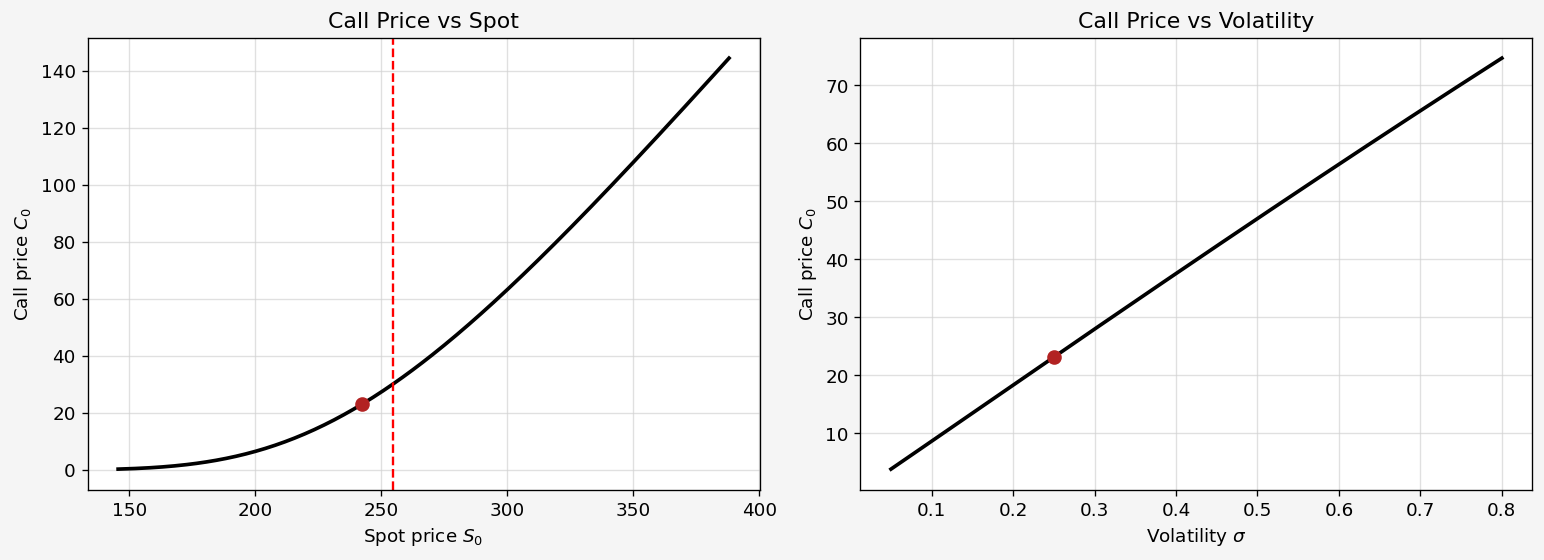

In [5]:
# -----------------------
# Combined Sensitivity Plot (2 panels)
# -----------------------

# Left panel: C0 as a function of S0
S_grid_price = np.linspace(0.6 * S0, 1.6 * S0, 250)
C_grid = np.array([bs_call_price(s, K, T, r, sigma) for s in S_grid_price])

# Right panel: C0 as a function of sigma
sigma_grid = np.linspace(0.05, 0.80, 250)
C_sigma = np.array([bs_call_price(S0, K, T, r, s) for s in sigma_grid])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), dpi=120)

# ---- LEFT: Call price vs Spot ----
ax1.plot(S_grid_price, C_grid, color="black", linewidth=2.2)
ax1.axvline(K, linestyle="--", color="red", linewidth=1.4)
ax1.scatter([S0], [C0], color="firebrick", s=60, zorder=5)

ax1.set_title("Call Price vs Spot")
ax1.set_xlabel("Spot price $S_0$")
ax1.set_ylabel("Call price $C_0$")
ax1.grid(True, alpha=0.7)

# ---- RIGHT: Call price vs Volatility ----
ax2.plot(sigma_grid, C_sigma, color="black", linewidth=2.2)
ax2.scatter([sigma], [C0], color="firebrick", s=60, zorder=5)

ax2.set_title("Call Price vs Volatility")
ax2.set_xlabel("Volatility $\\sigma$")
ax2.set_ylabel("Call price $C_0$")
ax2.grid(True, alpha=0.7)

plt.tight_layout()
plt.show()

### **Option Pricing**

So far, we derived the **closed-form Black–Scholes price** for a European call option under the assumptions of:
- frictionless markets,
- constant volatility,
- constant risk-free rate,
- no dividends,
- and Geometric Brownian Motion under the risk-neutral measure.

However, the Black–Scholes formula is only available in closed form for relatively simple derivatives.  
A more general numerical alternative is **Monte Carlo simulation**, which approximates the risk-neutral expectation directly.

Under the risk-neutral measure, the price of a European call is:

$$
C_0 = e^{-rT}\,\mathbb{E}^{\mathbb{Q}}[(S_T-K)^+].
$$

The idea of Monte Carlo pricing is simple:
1. simulate many possible terminal prices $S_T$ under the risk-neutral dynamics,
2. compute the payoff $(S_T-K)^+$ for each simulation,
3. average the payoffs,
4. discount them back to time $0$.

This gives a numerical approximation of the same quantity that Black–Scholes computes analytically.

In [6]:
# -----------------------
# Monte Carlo pricing functions
# -----------------------

def simulate_terminal_prices_rn(S0, T, r, sigma, n_sim=100000, seed=42):
    """
    Simulate terminal prices S_T under the risk-neutral GBM model:
        S_T = S0 * exp((r - 0.5*sigma^2)T + sigma*sqrt(T)*Z)
    """
    rng = np.random.default_rng(seed)
    Z = rng.standard_normal(n_sim)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    return ST

def mc_call_price(S0, K, T, r, sigma, n_sim=100000, seed=42):
    """
    Monte Carlo estimate of a European call option price.
    Returns:
        price, standard_error, ci_low, ci_high, ST, payoffs, discounted_payoffs
    """
    ST = simulate_terminal_prices_rn(S0, T, r, sigma, n_sim=n_sim, seed=seed)
    payoffs = np.maximum(ST - K, 0.0)
    discounted_payoffs = np.exp(-r * T) * payoffs

    price = discounted_payoffs.mean()
    std_error = discounted_payoffs.std(ddof=1) / np.sqrt(n_sim)
    ci_low = price - 1.96 * std_error
    ci_high = price + 1.96 * std_error

    return price, std_error, ci_low, ci_high, ST, payoffs, discounted_payoffs

### **Numerical Pricing and Comparison**

We now price the same European call option using both methods:

- **Black–Scholes**: analytical benchmark,
- **Monte Carlo**: simulation-based approximation.

If the implementation is correct, the Monte Carlo price should be close to the analytical Black–Scholes value, up to simulation error.  
The remaining difference is due to the fact that Monte Carlo uses a **finite number of random draws**, so it is an estimator rather than an exact formula.

In [7]:
# -----------------------
# Price comparison: Black-Scholes vs Monte Carlo
# -----------------------

n_sim = 200000

bs_call = bs_call_price(S0, K, T, r, sigma)
mc_call, mc_se, mc_ci_low, mc_ci_high, ST_mc, payoffs_mc, disc_payoffs_mc = mc_call_price(
    S0, K, T, r, sigma, n_sim=n_sim, seed=42
)

abs_diff = abs(bs_call - mc_call)
rel_diff = abs_diff / bs_call if bs_call != 0 else np.nan

print("European Call Pricing Comparison")
print("-" * 50)
print(f"S0        = {S0:.4f}")
print(f"K         = {K:.4f}")
print(f"T         = {T:.4f}")
print(f"r         = {r:.4f}")
print(f"sigma     = {sigma:.4f}")
print(f"Simulations = {n_sim:,}")
print("-" * 50)
print(f"Black-Scholes price     = {bs_call:.6f}")
print(f"Monte Carlo price       = {mc_call:.6f}")
print(f"Monte Carlo std. error  = {mc_se:.6f}")
print(f"95% confidence interval = [{mc_ci_low:.6f}, {mc_ci_high:.6f}]")
print(f"Absolute difference     = {abs_diff:.6f}")
print(f"Relative difference     = {100 * rel_diff:.4f}%")

European Call Pricing Comparison
--------------------------------------------------
S0        = 242.5252
K         = 254.6514
T         = 1.0000
r         = 0.0400
sigma     = 0.2500
Simulations = 200,000
--------------------------------------------------
Black-Scholes price     = 23.176327
Monte Carlo price       = 23.245046
Monte Carlo std. error  = 0.091129
95% confidence interval = [23.066434, 23.423659]
Absolute difference     = 0.068719
Relative difference     = 0.2965%


A useful diagnostic is to check whether the **Black–Scholes price lies inside the Monte Carlo confidence interval**.  
If it does, this is strong evidence that the simulation is correctly approximating the same risk-neutral expectation.

We can also inspect the simulated distribution of terminal prices $S_T$ and the corresponding option payoffs.  
Because the call payoff is truncated at zero, its distribution is asymmetric: many simulations may generate small or zero payoffs, while a smaller set of scenarios produces large positive outcomes.

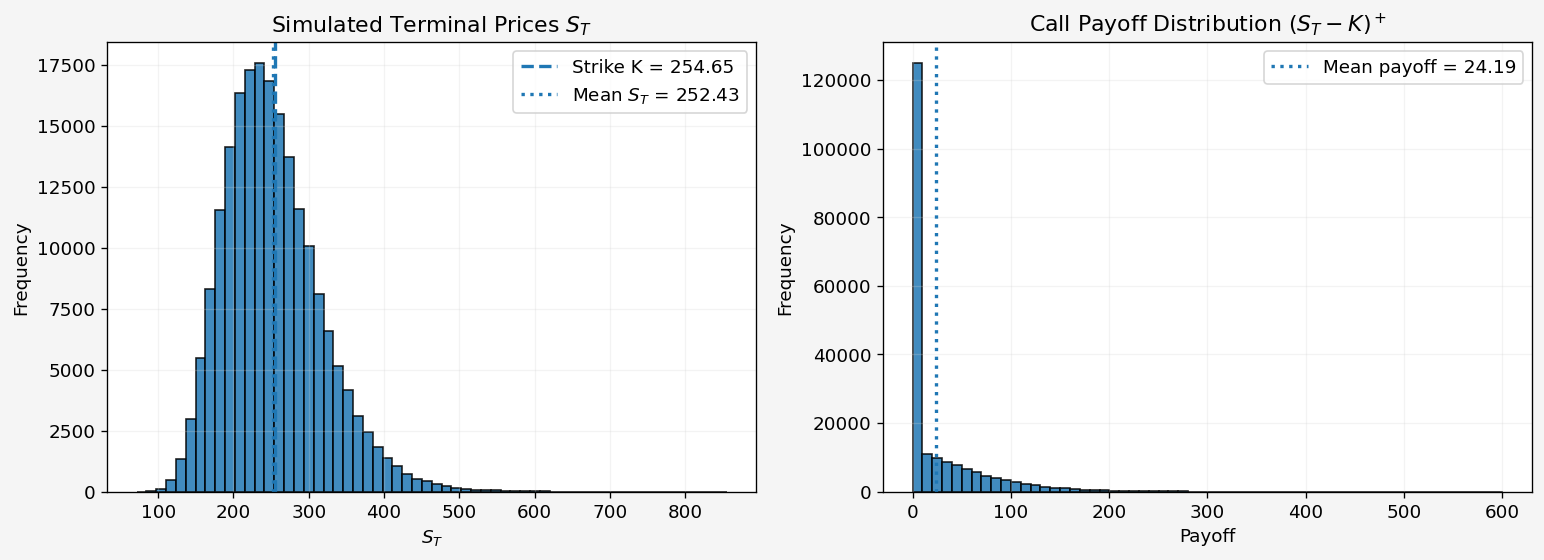

In [8]:
# -----------------------
# Distribution plots: terminal prices and payoffs
# -----------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=120)

# Terminal prices
axes[0].hist(ST_mc, bins=60, alpha=0.85, edgecolor="black")
axes[0].axvline(K, linestyle="--", linewidth=2, label=f"Strike K = {K:.2f}")
axes[0].axvline(ST_mc.mean(), linestyle=":", linewidth=2, label=f"Mean $S_T$ = {ST_mc.mean():.2f}")
axes[0].set_title("Simulated Terminal Prices $S_T$")
axes[0].set_xlabel("$S_T$")
axes[0].set_ylabel("Frequency")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Payoffs
axes[1].hist(payoffs_mc, bins=60, alpha=0.85, edgecolor="black")
axes[1].axvline(payoffs_mc.mean(), linestyle=":", linewidth=2, label=f"Mean payoff = {payoffs_mc.mean():.2f}")
axes[1].set_title("Call Payoff Distribution $(S_T-K)^+$")
axes[1].set_xlabel("Payoff")
axes[1].set_ylabel("Frequency")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

### **Convergence of the Monte Carlo Estimator**

By the **Law of Large Numbers**, the Monte Carlo estimator converges to the true option value as the number of simulations increases.

This is one of the key strengths of Monte Carlo methods:
- they are conceptually simple,
- they are flexible,
- and they remain applicable even when no closed-form pricing formula is available.

The tradeoff is computational: unlike Black–Scholes, Monte Carlo does not return an exact formula instantly, but an approximation that improves as the sample size grows.

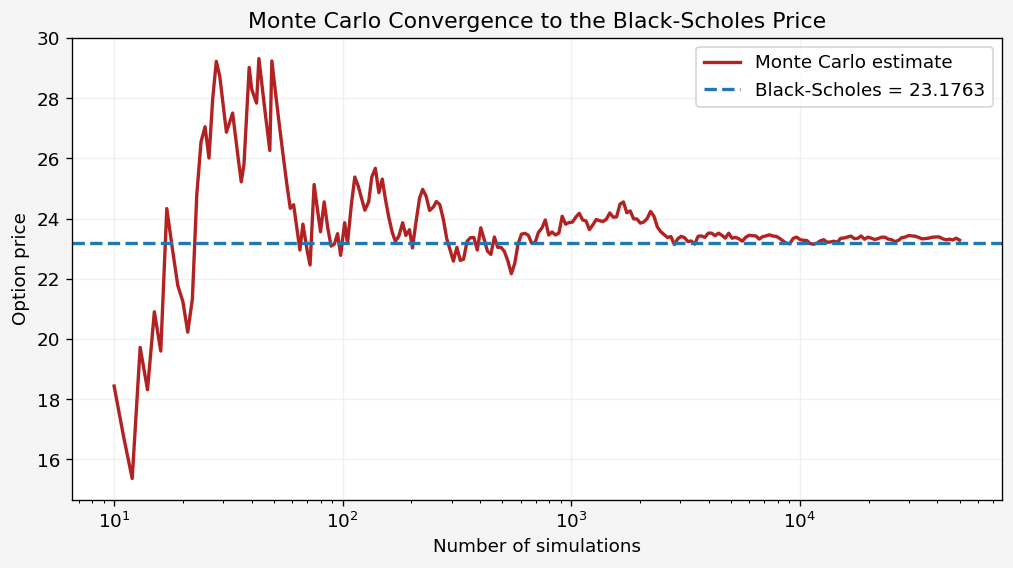

In [10]:
# -----------------------
# Convergence of Monte Carlo estimator
# -----------------------

rng = np.random.default_rng(123)
n_paths_conv = 50000

Z_conv = rng.standard_normal(n_paths_conv)
ST_conv = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z_conv)
disc_payoffs_conv = np.exp(-r * T) * np.maximum(ST_conv - K, 0.0)

running_mc = np.cumsum(disc_payoffs_conv) / np.arange(1, n_paths_conv + 1)

checkpoints = np.unique(np.geomspace(10, n_paths_conv, 250).astype(int))

plt.figure(figsize=(10, 5), dpi=120)
plt.plot(checkpoints, running_mc[checkpoints - 1], linewidth=2, label="Monte Carlo estimate", color="firebrick")
plt.axhline(bs_call, linestyle="--", linewidth=2, label=f"Black-Scholes = {bs_call:.4f}")
plt.xscale("log")
plt.xlabel("Number of simulations")
plt.ylabel("Option price")
plt.title("Monte Carlo Convergence to the Black-Scholes Price")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### **Final Takeaway**

The comparison shows two complementary approaches to option pricing:

- **Black–Scholes** provides a fast and elegant closed-form benchmark under restrictive assumptions.
- **Monte Carlo** approximates the same risk-neutral expectation numerically and is much more flexible in more complex settings.

In this notebook, both methods produce closely aligned results for a European call, which is exactly what we should expect when the simulation is performed under the same model assumptions.

This analytical-versus-numerical comparison is useful because it highlights an important idea in quantitative finance:  
the pricing problem often remains the same, while the **method used to compute the expectation** may change depending on the complexity of the derivative.